In [5]:
import os
import scipy.stats as stats
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import PowerTransformer

from Regression_utils import *


In [6]:
main_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data.xlsx")
print(main_df.columns)

Index(['Name', 'Year-Month', 'Hours', 'Water Total', 'PSI', 'Revenue',
       'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH', 'Fuel Rate',
       'Electrical Bill', 'Workover Info', 'Workover Cost', 'Pump Model',
       'Pump Number', 'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'KWH per Barrel', 'Cost per KWH',
       'Electrical Cost per Barrel', 'Maintenance Cost per Barrel',
       'Workover Cost per Barrel', 'Revenue per Barrel', 'Income per Barrel',
       'Income', 'Total Cost', '6 Month Avg Water Total', '6 Month Avg KWH',
       '6 Month Avg Revenue', '6 Month Avg Income', '6 Month Avg Total Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Month Avg Workover Cost per Barrel',
       '6 Month Avg Revenue per Barrel', '6 Month Avg Income per Barrel',
       'Cumulative Electrical Cost', 'Cumul

In [7]:

main_df["Workover Count"] = np.where(
    main_df["Workover Cost"] > 1, 
    1, 
    0
)
# matplotlib doesn't like the pure string values for Year-Month
main_df["Date"] = pd.to_datetime(main_df["Year-Month"])
main_df["Period"] = pd.to_datetime(main_df["Year-Month"]).dt.to_period(freq="M")
print(main_df["Period"])

main_df["Year-Month"] = main_df["Year-Month"].dt.to_period("M")

# Get a count of workovers for each well
print(main_df.groupby("Name")["Workover Count"].sum())
workover_counts = main_df.groupby("Name")["Workover Count"].sum()
workover_counts.hist()

0       2017-08
1       2017-09
2       2017-10
3       2017-11
4       2017-12
         ...   
8521    2025-05
8522    2025-06
8523    2025-07
8524    2025-08
8525    2025-09
Name: Period, Length: 8526, dtype: period[M]


AttributeError: Can only use .dt accessor with datetimelike values

In [8]:
#Date Processing
main_df2 = main_df.copy()
names_to_drop = ["BOLDRICK #1", "BOLDRICK #2", "COLVILLE #5", "FIELDS #4", "KEE #4", 
                 "KEE #5", "MOYAR #3", "SHAW #4", "SUNKEL #4", "WILLIAMS #6", "WILSON #4", 
                 "HUGHES #4", "KEE #6", "LAKE #6", "MOYAR #2", "PAYNE #7", "WILLIAMS #2", "WILLIAMS #9"
                ]

# Filtering the data to between pre and post workover.
#KWH_filt = KWH_df.drop((KWH_df["Workover Count"] > 0) & (KWH_df["Workover Count"] <2))
#KWH_filt.tail()
main_df["First Workover Date"] = pd.to_datetime("2000-01", format = "%Y-%m")
main_df["First Workover Date"] = main_df["First Workover Date"].dt.to_period("M")
wells = main_df["Name"].unique()
#print(wells)
#Assigning workover dates to each well
for well in wells:
    well_filt = main_df["Name"] == well
    work_filt = main_df["Workover Count"] == 1
    full_filt = (well_filt) & (work_filt)
    main_df[full_filt]["Year-Month"]
    if len(main_df[full_filt]) == 1:
        main_df.loc[full_filt, "First Workover Date"] = main_df[full_filt]["Year-Month"]
        print(well, " 1")
        print(main_df[full_filt]["First Workover Date"])
    elif len(main_df[full_filt]) > 1:
        # first date = first workover date
        # second date = second workover date
        first_date = main_df.loc[full_filt, "Year-Month"].iloc[0]
        second_date = main_df.loc[full_filt, "Year-Month"].iloc[1]

        
        main_df.loc[full_filt, "First Workover Date"] = first_date
        main_df.loc[full_filt, "Second Workover Date"] = second_date
        
        print(well, "> 1")
        print(main_df.loc[full_filt, "First Workover Date"])
        print(main_df.loc[full_filt, "Second Workover Date"])

    

ABNEY #3  1
193    2025-07
Name: First Workover Date, dtype: period[M]
ALBERTSON #4  1
255    2022-07
Name: First Workover Date, dtype: period[M]
BASS #5  1
417    2019-09
Name: First Workover Date, dtype: period[M]
BLUM #7  1
1254    2024-02
Name: First Workover Date, dtype: period[M]
BOLDRICK #1 > 1
1372    2017-08
1400    2017-08
Name: First Workover Date, dtype: period[M]
1372    2019-12
1400    2019-12
Name: Second Workover Date, dtype: str
BOLDRICK #2 > 1
1486    2018-12
1518    2018-12
Name: First Workover Date, dtype: period[M]
1486    2021-08
1518    2021-08
Name: Second Workover Date, dtype: str
BOLES #1  1
1764    2017-08
Name: First Workover Date, dtype: period[M]
COLVILLE #4  1
2214    2022-06
Name: First Workover Date, dtype: period[M]
COLVILLE #5 > 1
2312    2022-06
2320    2022-06
Name: First Workover Date, dtype: period[M]
2312    2023-02
2320    2023-02
Name: Second Workover Date, dtype: str
CUNYUS #4 > 1
2685    2020-11
2706    2020-11
2712    2020-11
2737    2020-11

156


<function matplotlib.pyplot.show(close=None, block=None)>

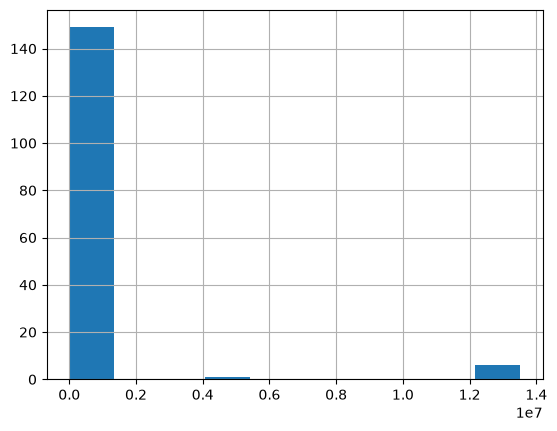

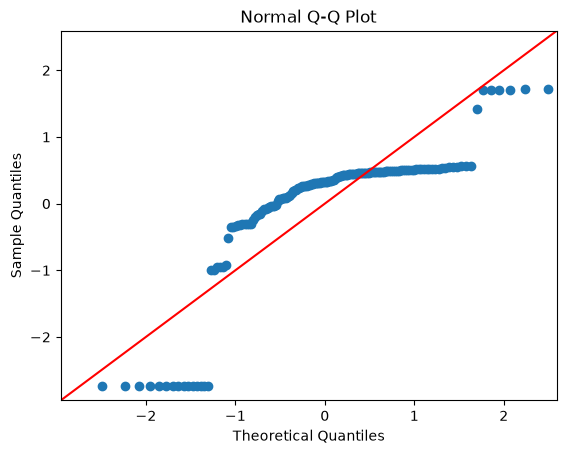

In [27]:
# data distribution tests
# Billing KWH
# before workover
print(len(total_before_df))
total_before_df["Billing KWH"].hist()
data = np.log1p(total_before_df["Billing KWH"])
sm.qqplot(data, fit = True, line = "45")

plt.title("Normal Q-Q Plot")
plt.show

156


<function matplotlib.pyplot.show(close=None, block=None)>

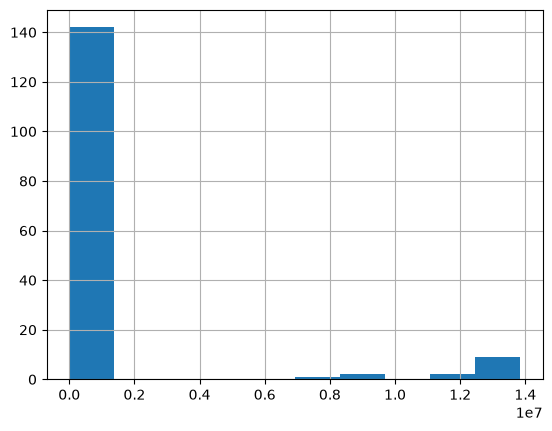

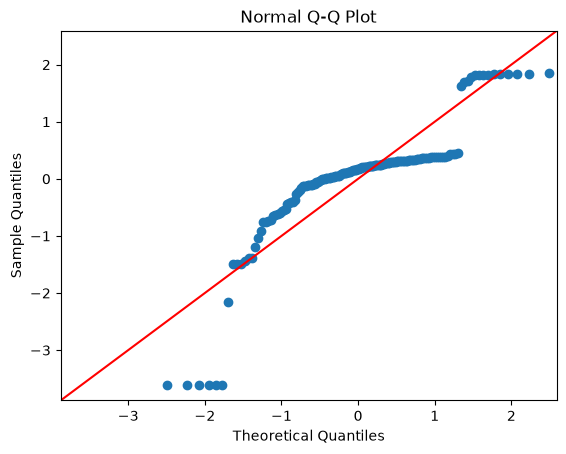

In [20]:
# data distribution tests
# Billing KWH
# after workover
print(len(total_after_df))
total_after_df["Billing KWH"].hist()
data = np.log1p(total_after_df["Billing KWH"])
sm.qqplot(data, fit = True, line = "45")

plt.title("Normal Q-Q Plot")
plt.show

In [33]:
# Using a Wilcoxon test: non-parametric stats method used to compare two groups or conditions when the data does not follow a normal distribution
total_before_df = total_before_df.reset_index(drop=True)
total_after_df = total_after_df.reset_index(drop=True)

diff = total_after_df["Billing KWH"].to_numpy() - total_before_df["Billing KWH"].to_numpy()
total_before_df.dropna()
total_after_df.dropna()
stats.wilcoxon(total_before_df["Billing KWH"], total_after_df["Billing KWH"])




WilcoxonResult(statistic=np.float64(5835.0), pvalue=np.float64(0.8110970087412899))

In [10]:
#Paired t-test for the wells with 1 workover
before_list = []
after_list = []

# dataframes designed to show values 6 months before and after workovers for all wells
total_before_df = pd.DataFrame()
total_after_df = pd.DataFrame()

# Paired T-test for first workover date
for well in wells:
    # Filter to this well
    well_filt = main_df["Name"] == well
    well_df = main_df[well_filt].sort_values("Year-Month").reset_index(drop=True)

    # Find the row(s) where Year-Month matches the workover date
    date_filt = well_df["Year-Month"] == well_df["First Workover Date"]
    workover_rows = well_df[well_df["Workover Count"] == 1]

    

    if workover_rows.empty:
        # No matching workover date found for this well — skip
        continue

        
    # Get the integer position of the workover month
    workover_idx = workover_rows.index[0]

    # Slice 6 months before (not including workover month)
    before_df = well_df.iloc[max(0, workover_idx - 6):workover_idx]

    # Slice 6 months after (not including workover month)
    after_df = well_df.iloc[workover_idx + 1: workover_idx + 7]

       # Only keep this well if it has a FULL 6 months on both sides
    if len(before_df) == 6 and len(after_df) == 6:
        # concatenate the 6 months before and after workover for each well into a single dataframe
        total_before_df = pd.concat([total_before_df, before_df])
        total_after_df = pd.concat([total_after_df, after_df])
        
        before_list.append(before_df)
        after_list.append(after_df)

        KWH_before = before_df["Billing KWH"].to_numpy()
        KWH_after = after_df["Billing KWH"].to_numpy()
        # Paired T-test for Billing KWH 6-months before and after workover 
        # Significant: Albertson #4, Boldrick #2, Hamon #2, Payne #5, Sunkel #3, Wilson #4
        #print(well, stats.ttest_rel(KWH_before, KWH_after))

        Ebill_before = before_df["Electrical Bill"].to_numpy()
        Ebill_after = after_df["Electrical Bill"].to_numpy()
        # Paired T-test for Electric bill 6-months before and after workover
        # Significant: Albertson #4, Bass #5, Cunyus #6, Downing #2, Payne #5, Sunkel #4
        # Results (Nan) = Sharp #8, Sunkel #3
        #print(well, stats.ttest_rel(Ebill_before, Ebill_after))

        MetDM_before = before_df["Metered DM"].to_numpy()
        MetDM_after = after_df["Metered DM"].to_numpy()
        # Paired T-test for Metered Demand 6-months before and after workover
        # Significant: Bass#5, Boldrick #2, Downing #2, Fields #4, Hamon #2, Moyar #3, Payne #5, Thompson #3, Williams #11, Wilson #4
        # Results (Nan) = Sharp #8, Sunkel #3
        print(well, stats.ttest_rel(MetDM_before, MetDM_after))





ALBERTSON #4 TtestResult(statistic=np.float64(21.00639210759632), pvalue=np.float64(4.5295909986219055e-06), df=np.int64(5))
BASS #5 TtestResult(statistic=np.float64(7.519983509003453), pvalue=np.float64(0.0006580602010981257), df=np.int64(5))
BLUM #7 TtestResult(statistic=np.float64(0.2698301705720949), pvalue=np.float64(0.7980731696523659), df=np.int64(5))
BOLDRICK #2 TtestResult(statistic=np.float64(-3.7703224194886857), pvalue=np.float64(0.013018607370714776), df=np.int64(5))
COLVILLE #4 TtestResult(statistic=np.float64(-0.4420056904506299), pvalue=np.float64(0.6769481585089379), df=np.int64(5))
COLVILLE #5 TtestResult(statistic=np.float64(1.2823007845327954), pvalue=np.float64(0.255968611057274), df=np.int64(5))
CUNYUS #4 TtestResult(statistic=np.float64(-1.0741723110591492), pvalue=np.float64(0.33182682121419566), df=np.int64(5))
CUNYUS #6 TtestResult(statistic=np.float64(-0.455716363245514), pvalue=np.float64(0.6677022397670576), df=np.int64(5))
DOWNING #2 TtestResult(statistic=

In [11]:
# Paired T-test for the second workover date 
for well in wells:
    # Filter to this well
    well_filt = main_df["Name"] == well
    well_df = main_df[well_filt].sort_values("Year-Month").reset_index(drop=True)

    # Find the row(s) where Year-Month matches the workover date
    date_filt = well_df["Year-Month"] == well_df["Second Workover Date"]
    workover_rows = well_df[date_filt] 
    
    if workover_rows.empty:
        # No matching workover date found for this well — skip
        continue

    # Get the integer position of the workover month
    workover_idx = workover_rows.index[0]

    # Slice 6 months before (not including workover month)
    before_df = well_df.iloc[max(0, workover_idx - 6):workover_idx]

    # Slice 6 months after (not including workover month)
    after_df = well_df.iloc[workover_idx + 1: workover_idx + 7]

       # Only keep this well if it has a FULL 6 months on both sides
    if len(before_df) == 6 and len(after_df) == 6:
        before_list.append(before_df)
        after_list.append(after_df)
        
        KWH_before = before_df["Billing KWH"].to_numpy()
        KWH_after = after_df["Billing KWH"].to_numpy()
        # Paired t-test of Billing KWH before and after the second workover date
        # Significant: Colville #5, Kee #6, Payne #5, Payne #7, Shaw #4, Sunkel #4, Williams #6, Wilson #4
        #print(well, stats.ttest_rel(KWH_before, KWH_after))

        Ebill_before = before_df["Electrical Bill"].to_numpy()
        Ebill_after = after_df["Electrical Bill"].to_numpy()
        #CLeaning for nan values in the array
        Ebill_before_clean = Ebill_before[~np.isnan(Ebill_before)]
        Ebill_after_clean = Ebill_after[~np.isnan(Ebill_after)]
        # Paired t-test of Electrical Bill before and after the second workover date
        # Significant: Boldrick #2, Payne #5, Payne #7, Shaw #4, Sunkel #4, Williams #6, Wilson #4
        # Result (Nan): Kee #6, Williams #2 (Due to a lack of significance in the data!)
        #print(well, stats.ttest_rel(Ebill_before_clean, Ebill_after_clean))
        
        
        
        
        MetDM_before = before_df["Metered DM"].to_numpy()
        MetDM_after = after_df["Metered DM"].to_numpy()
        MetDM_before_clean = MetDM_before[~np.isnan(MetDM_before)]
        MetDM_after_clean = MetDM_after[~np.isnan(MetDM_after)]
        # Paired t-test of Metered Demand before and after the second workover date
        #Significant: Payne #7
        #Result (Nan): Kee #6, Williams #2 (Due to the arrays being empty, could be from a lack of observations)
        print(well, stats.ttest_rel(MetDM_before, MetDM_after))

BOLDRICK #1 TtestResult(statistic=np.float64(-0.3718182996118766), pvalue=np.float64(0.7252650921516233), df=np.int64(5))
BOLDRICK #2 TtestResult(statistic=np.float64(2.361825885891912), pvalue=np.float64(0.06460446169413678), df=np.int64(5))
COLVILLE #5 TtestResult(statistic=np.float64(1.9080819424304416), pvalue=np.float64(0.11466805602308924), df=np.int64(5))
CUNYUS #4 TtestResult(statistic=np.float64(0.49555985287345533), pvalue=np.float64(0.6412145721163045), df=np.int64(5))
FIELDS #4 TtestResult(statistic=np.float64(1.4411533842457842), pvalue=np.float64(0.20910419544041015), df=np.int64(5))
HUGHES #4 TtestResult(statistic=np.float64(-0.8864578811753856), pvalue=np.float64(0.4159653397262158), df=np.int64(5))
KEE #4 TtestResult(statistic=np.float64(1.7096421332911045), pvalue=np.float64(0.14802534243590604), df=np.int64(5))
KEE #5 TtestResult(statistic=np.float64(0.26359094309269065), pvalue=np.float64(0.8026135115016905), df=np.int64(5))
KEE #6 TtestResult(statistic=np.float64(n

In [12]:
# Aggregate paried t-test - 6 Months before and after

vars = ["Billing KWH", "Electrical Bill", "Metered DM"]

for var in vars:
    print(f"{var} before and after 6-month paired t-test")
    print(stats.ttest_rel(total_before_df[var], total_after_df[var]))

Billing KWH before and after 6-month paired t-test
TtestResult(statistic=np.float64(-2.6364284164668152), pvalue=np.float64(0.009230911096838835), df=np.int64(155))
Electrical Bill before and after 6-month paired t-test
TtestResult(statistic=np.float64(0.32290086018987973), pvalue=np.float64(0.7472055031996627), df=np.int64(155))
Metered DM before and after 6-month paired t-test
TtestResult(statistic=np.float64(nan), pvalue=np.float64(nan), df=np.float64(nan))


In [13]:
# Aggregate paired T-test - SINGLE MONTH ONLY
KWH_before_list = []
KWH_after_list = []

Ebill_before_list = []
Ebill_after_list = []

MetDM_before_list = []
MetDM_after_list = []

well_names = []

for well in wells:

    well_df = (
        main_df[main_df["Name"] == well]
        .sort_values("Year-Month")
        .reset_index(drop=True)
    )

    # Find the workover month
    date_filt = well_df["Year-Month"] == well_df["First Workover Date"]
    workover_rows = well_df[date_filt]

    if workover_rows.empty:
        continue

    workover_idx = workover_rows.index[0]

    # One month before workover
    before_df = well_df.iloc[workover_idx - 1:workover_idx]

    # One month after workover
    # Excludes the workover month itself
    after_df = well_df.iloc[workover_idx + 1:workover_idx + 2]

    # Require one month before and one month after
    if len(before_df) == 1 and len(after_df) == 1:

        # Billing KWH
        KWH_before_list.append(before_df["Billing KWH"].iloc[0])
        KWH_after_list.append(after_df["Billing KWH"].iloc[0])

        # Electrical Bill
        Ebill_before_list.append(before_df["Electrical Bill"].iloc[0])
        Ebill_after_list.append(after_df["Electrical Bill"].iloc[0])

        # Metered Demand
        MetDM_before_list.append(before_df["Metered DM"].iloc[0])
        MetDM_after_list.append(after_df["Metered DM"].iloc[0])

        # Well name
        well_names.append(well)


# Convert lists to arrays
KWH_before = np.array(KWH_before_list)
KWH_after = np.array(KWH_after_list)

Ebill_before = np.array(Ebill_before_list)
Ebill_after = np.array(Ebill_after_list)

MetDM_before = np.array(MetDM_before_list)
MetDM_after = np.array(MetDM_after_list)

print(len(KWH_before), len(KWH_after))
# Remove NaN pairs from Metered Demand
valid = ~np.isnan(MetDM_before) & ~np.isnan(MetDM_after)

MetDM_before_clean = MetDM_before[valid]
MetDM_after_clean = MetDM_after[valid]


# Paired t-tests across all qualifying wells
print(
    "KWH Aggregate:",
    stats.ttest_rel(KWH_before, KWH_after, nan_policy="omit")
)

print(
    "Electrical Bill Aggregate:",
    stats.ttest_rel(Ebill_before, Ebill_after, nan_policy="omit")
)

print(
    "Metered Demand Aggregate:",
    stats.ttest_rel(MetDM_before_clean, MetDM_after_clean)
)


32 32
KWH Aggregate: TtestResult(statistic=np.float64(-1.184902452456642), pvalue=np.float64(0.24506063944753137), df=np.int64(31))
Electrical Bill Aggregate: TtestResult(statistic=np.float64(-1.1354214016065338), pvalue=np.float64(0.26490140339533225), df=np.int64(31))
Metered Demand Aggregate: TtestResult(statistic=np.float64(-1.7616739306001525), pvalue=np.float64(0.08866507253199352), df=np.int64(29))


2022-07
<class 'pandas.Period'>
571.17647058824
<class 'numpy.float64'>
Series([], Name: PSI, dtype: float64)


NameError: name 'ticker' is not defined

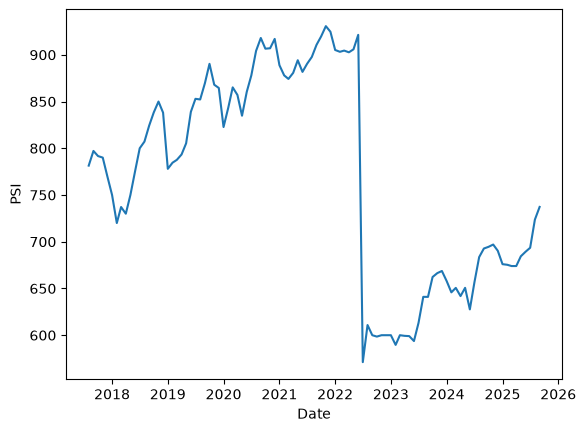

In [14]:
# Albertson 4 test - 1 workover existing
ab_filt = main_df["Name"] == "ALBERTSON #4"

# explicitly create a copy of the dataframe
filt_df = main_df.loc[ab_filt].copy()

# calling .loc returns a Series even if it is only one value returned
# calling iloc with a specific index on a specific column returns a value
workover_date = filt_df.loc[filt_df["Workover Count"] == 1, "Period"].iloc[0]
workover_psi = filt_df.loc[filt_df["Period"] == workover_date, "PSI"].iloc[0]

print(workover_date)
print(type(workover_date))
print(workover_psi)
print(type(workover_psi))
    
print(filt_df.loc[filt_df["Year-Month"] == workover_date, "PSI"])

fig, ax1 = plt.subplots(sharey=True)

ax1.plot(filt_df["Date"], filt_df["PSI"], label="PSI")
ax1.set_xlabel("Date")
ax1.set_ylabel("PSI")
ax1.xaxis.set_major_locator(ticker.MaxNLocator(16))
ax1.xaxis.set_major_formatter(mpldates.DateFormatter("%Y-%m"))
ax1.tick_params(axis="x", rotation=75)
ax1.annotate(
    "Workover",
    # xy is the coordinate for the annotation arrow/symbol
    xy=(workover_date, workover_psi),
    # xytext is the coordinate for the annotation text
    xytext=(workover_date, workover_psi + 10)
)
# convert Year-Month into ordinal values for y = mx + b calc
#filt_df["period-ordinal"] = filt_df["Year-Month"].ordinal

# Split data into pre and post workover - set the date as 1 month before the workover.
# This is done because the workover count is set based on when a charge was incurred,
# but the actual work may have taken place earlier.
pre_filt = filt_df["Period"] < (workover_date - 1)
pre_df = filt_df[pre_filt]
post_df = filt_df[~pre_filt]

# fit line to data
lm = np.polynomial.Polynomial.fit(pre_df.index, pre_df["PSI"], deg=1)
y_pred = lm(filt_df[~pre_filt].index)

# convert Year-Month into ordinal values for y = mx + b calc
ax1.plot(post_df["Date"], y_pred, label="Predicted PSI")

ax2 = ax1.twinx()
ax2.scatter(filt_df["Date"], filt_df["Disposal Rate"], color="green", edgecolor="black", label="Disposal Rate")
ax2.set_ylabel("Barrels/Hour")
fig.legend()

C:\Users\jroland\AppData\Local\Temp\ipykernel_27868\1004174307.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax1 = plt.subplots(sharey=True)


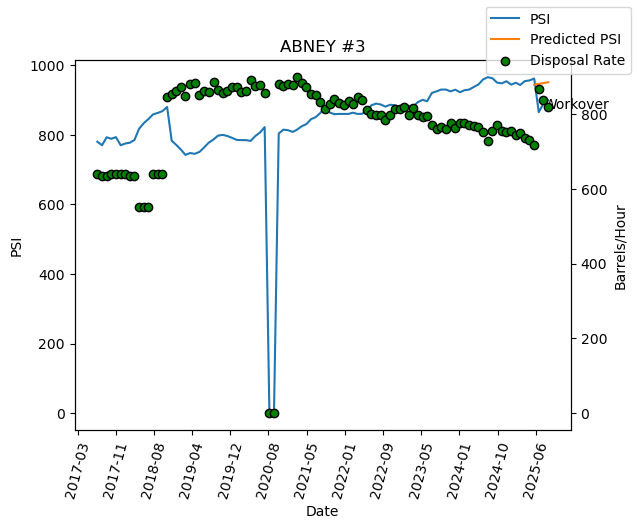

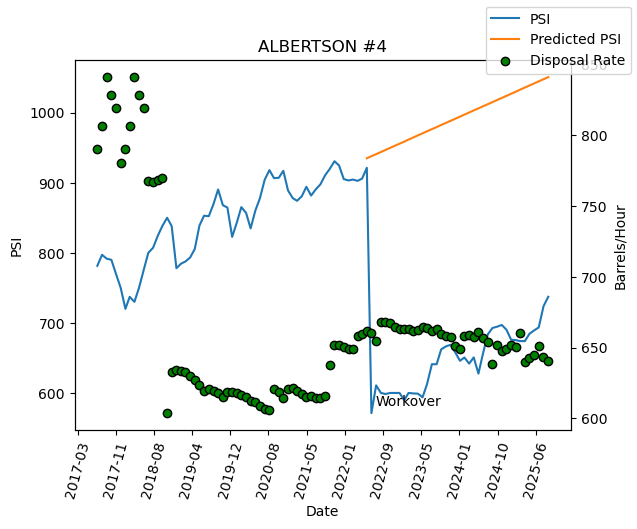

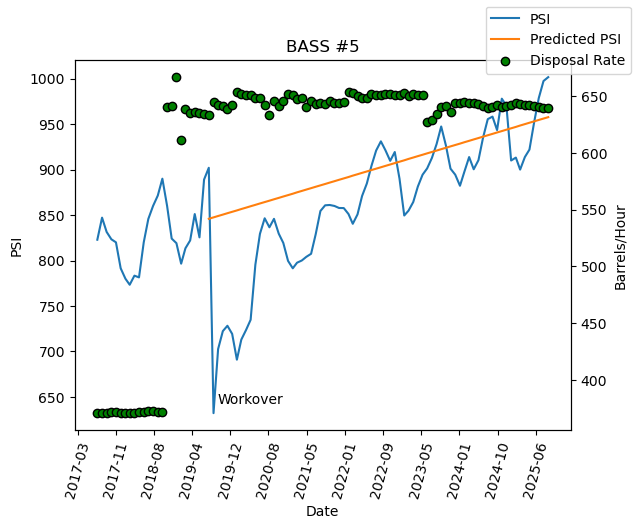

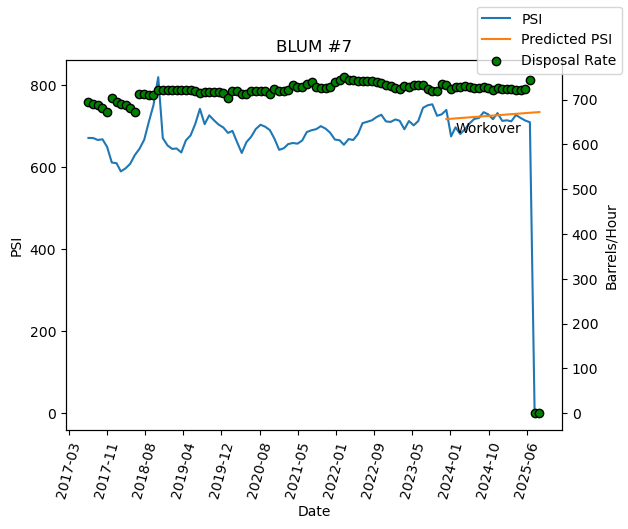

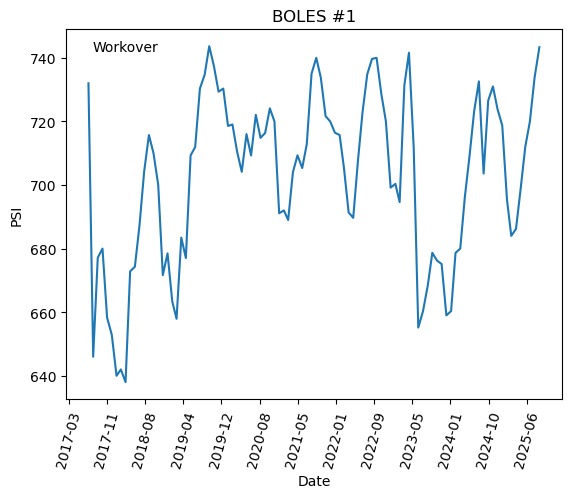

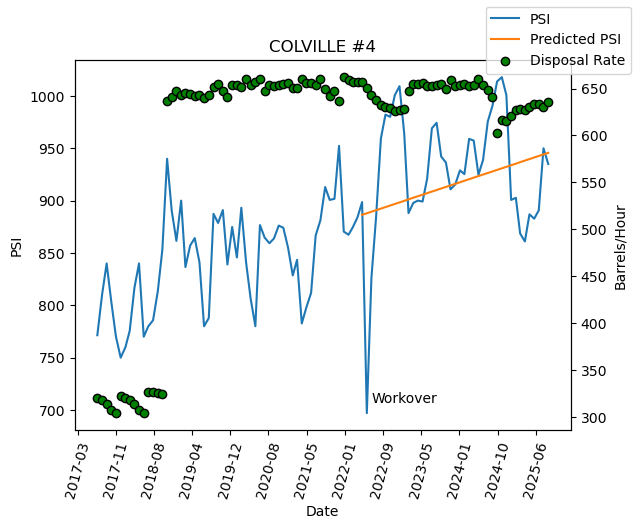

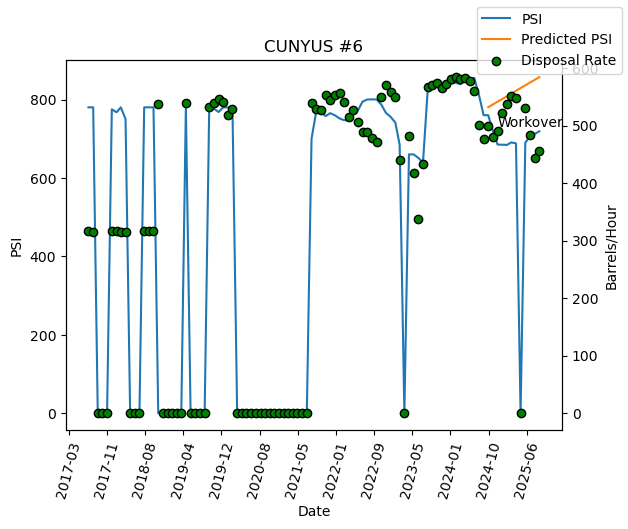

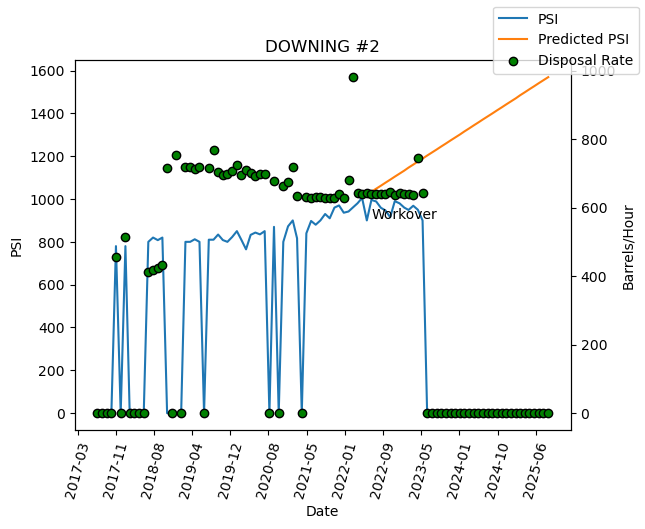

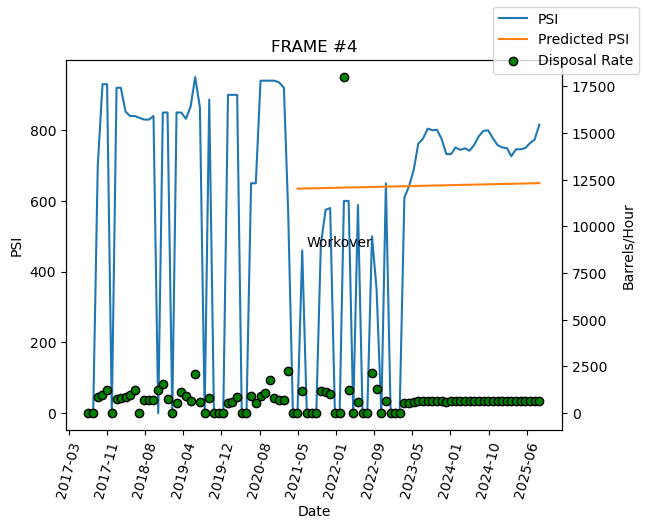

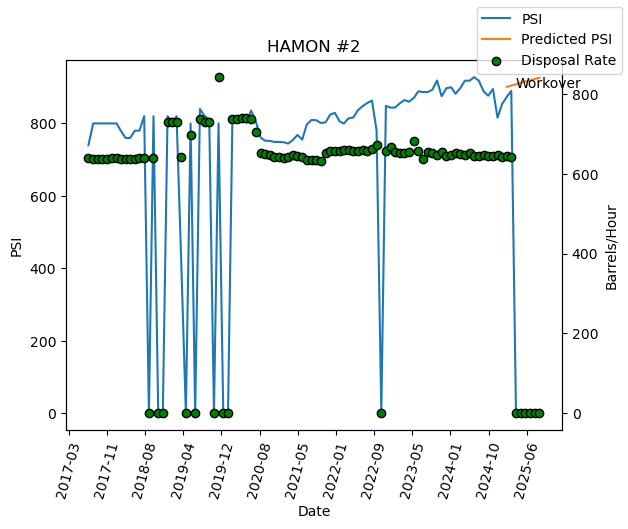

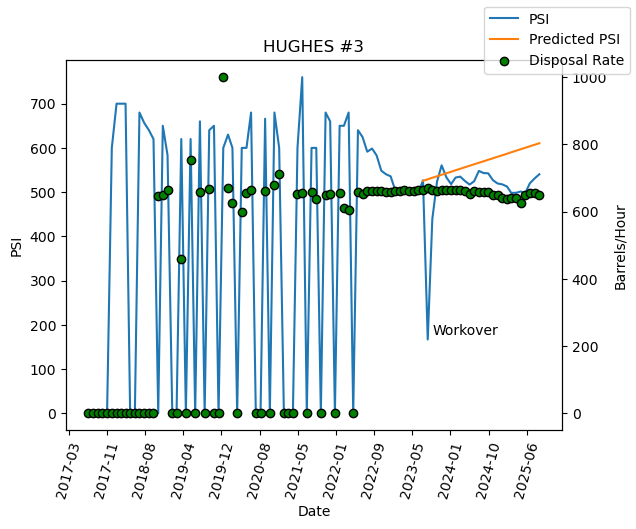

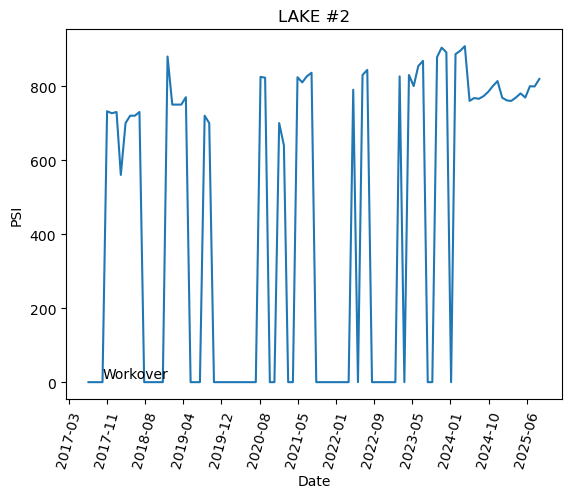

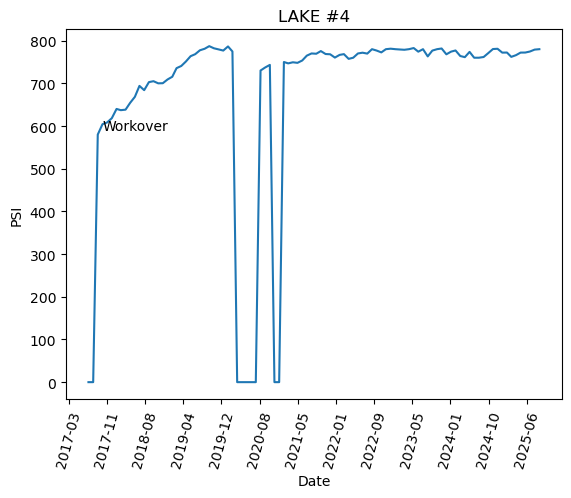

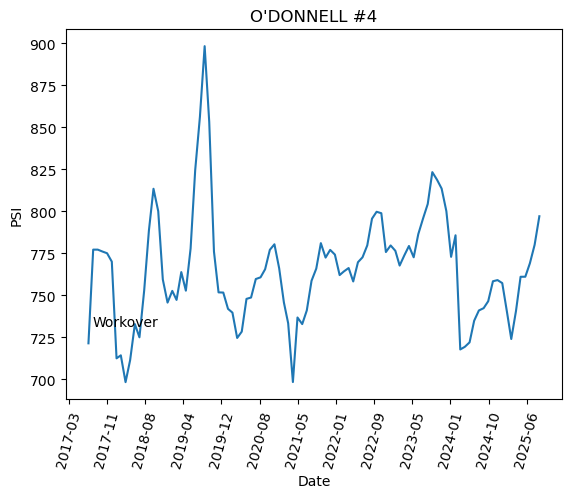

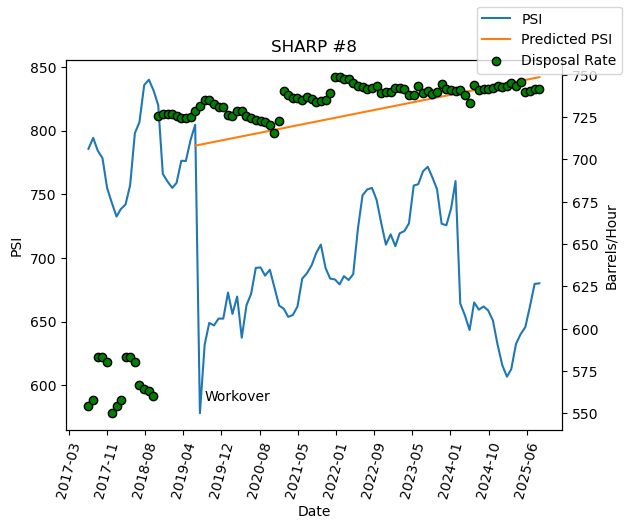

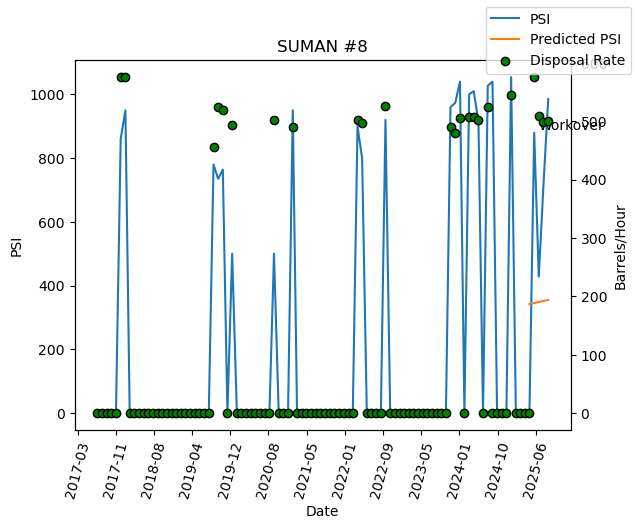

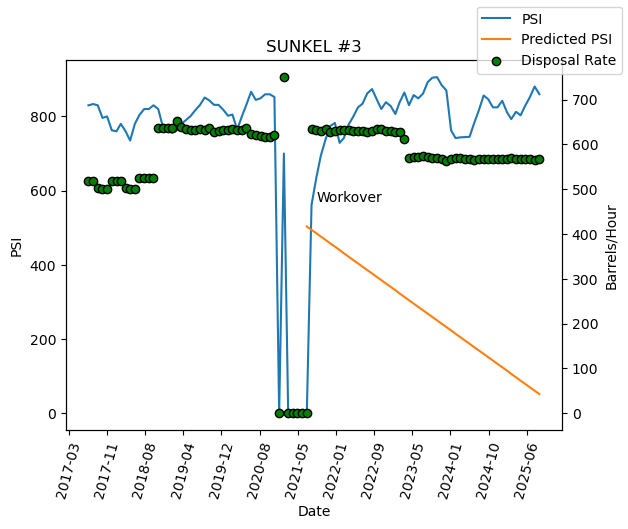

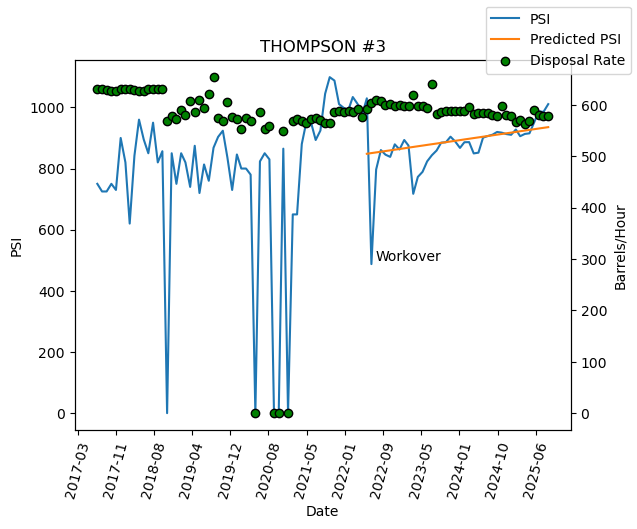

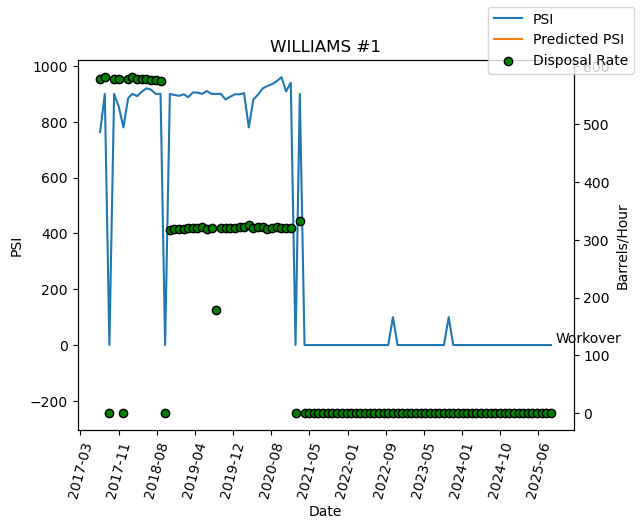

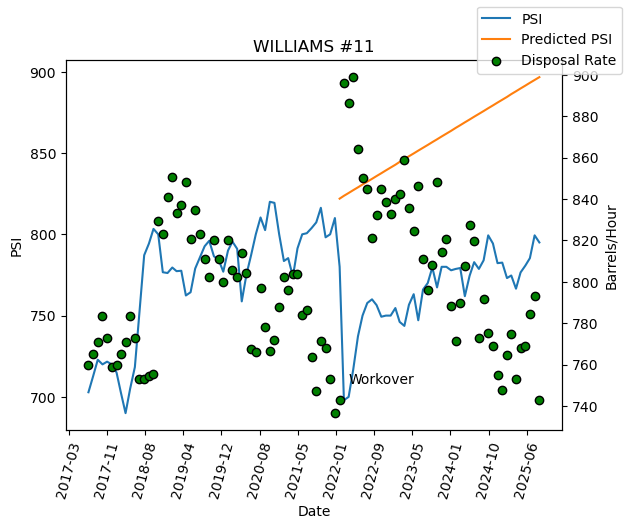

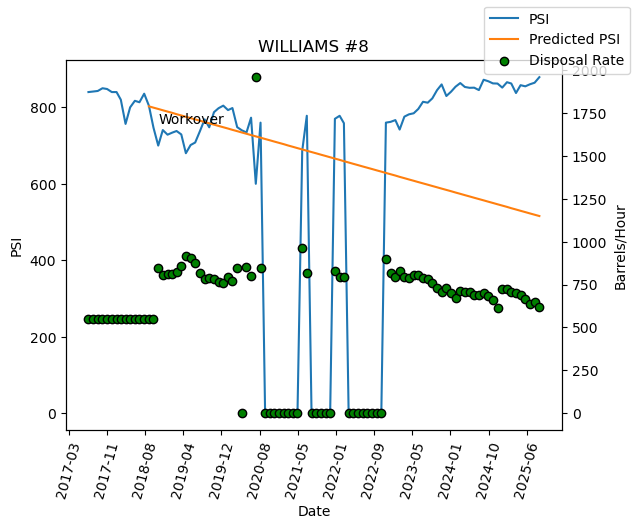

In [123]:
# apply previous method to all wells where workover count = 1
single_filt = main_df["Workover Count"] == 1

# NOTE: This will ONLY return the entry where workover count = 1, not all of the
# entries for a well that has had a workover.
single_workover_df = main_df[single_filt]

wells = workover_counts[workover_counts == 1].index

for well in wells:
    filtered_df = main_df.loc[main_df["Name"] == well, :]
    
    workover_date = filtered_df.loc[filtered_df["Workover Count"] == 1, "Period"].iloc[0]
    workover_psi = filtered_df.loc[filtered_df["Period"] == workover_date, "PSI"].iloc[0]
    
    fig, ax1 = plt.subplots(sharey=True)
    
    ax1.plot(filtered_df["Date"], filtered_df["PSI"], label="PSI")
    ax1.set_xlabel("Date")
    ax1.set_ylabel("PSI")
    ax1.set_title(well)
    ax1.xaxis.set_major_locator(ticker.MaxNLocator(16))
    ax1.xaxis.set_major_formatter(mpldates.DateFormatter("%Y-%m"))
    ax1.tick_params(axis="x", rotation=75)
    ax1.annotate(
        "Workover",
        # xy is the coordinate for the annotation arrow/symbol
        xy=(workover_date, workover_psi),
        # xytext is the coordinate for the annotation text
        xytext=(workover_date, workover_psi + 10)
    )

    pre_filt = filtered_df["Period"] < (workover_date - 1)
    pre_df = filtered_df[pre_filt]
    post_df = filtered_df[~pre_filt]

    if len(pre_df) > 1 and len(post_df) > 1:
                
        # fit line to data
        lm = np.polynomial.Polynomial.fit(pre_df.index, pre_df["PSI"], deg=1)
        y_pred = lm(post_df.index)
        
        ax1.plot(post_df["Date"], y_pred, label="Predicted PSI")
        
        ax2 = ax1.twinx()
        ax2.scatter(filtered_df["Date"], filtered_df["Disposal Rate"], color="green", edgecolor="black", label="Disposal Rate")
        ax2.set_ylabel("Barrels/Hour")
        fig.legend()
    